# Deep Learning Numericals Solved by Hand: CNNs, RNNs, LSTMs and Attention (Part 2)

> **Who is this for:** students preparing for deep-learning exams, quizzes and interviews who want to compute convolutions, parameter counts, recurrent steps and attention with pen and paper. Every problem uses tiny numbers.
>
> **What you will learn:**
> - the convolution output-size formula, and how padding and stride change it
> - a 2-D convolution computed by hand (stride 1; padding with stride 2; two input channels), plus max, average and global average pooling
> - how to count the parameters of dense, convolutional, recurrent and batch-norm layers, and of a small complete CNN
> - one or two time steps of a simple RNN, and one full LSTM step with all four gates
> - scaled dot-product attention for 3 tokens: scores, scaling by $\sqrt{d_k}$, softmax and the weighted sum
> - cosine similarity between word vectors, and perplexity from token probabilities
>
> **Prerequisites:** [Deep learning numericals, part 1](00b_dl_numericals_solved_by_hand.ipynb) (neurons, activations, softmax, backprop, vanishing gradients), [PyTorch from zero](00_start_here_pytorch_from_zero.ipynb), and [ML numericals solved by hand](../03_Machine_Learning/00c_ml_numericals_solved_by_hand.ipynb).
>
> **Time needed:** about 45 minutes to read, 2 hours if you solve every "Try it yourself" problem on paper.
>
> **Runs on:** CPU, no API key, no internet. Only NumPy and matplotlib; the whole notebook runs in a few seconds.
>
> **Going further:** these sections stay at the basic level. For more computer-vision numericals (IoU, non-max suppression, receptive fields, 1x1 convolution cost) see [CV numericals](../06_Computer_Vision/00b_cv_numericals_solved_by_hand.ipynb); for word2vec, BLEU, beam search and n-grams see [NLP numericals](../07_NLP/00b_nlp_numericals_solved_by_hand.ipynb); for Transformer parameters, KV cache, LoRA and sampling see [LLM and GenAI numericals](../08_LLM/00b_llm_and_genai_numericals_solved_by_hand.ipynb).

## Explained simply

Part 1 used networks that see a flat list of numbers. Real data often has **structure**:

- An **image** is a grid of pixels. A **convolutional network (CNN)** slides a small window of weights (a *filter* or *kernel*) across the grid, so the same pattern detector is reused everywhere, like reading a page with a magnifying glass that is trained to spot one shape.
- A **sentence** or a **time series** is a sequence. A **recurrent network (RNN, LSTM)** reads it one step at a time and carries a memory (the *hidden state*) from step to step, like reading a book and keeping a running summary in your head.
- **Attention** lets every token look at every other token and decide how much each one matters, like scanning a room and paying most attention to the people who are talking about your topic.

All of them are still built from the same pieces as Part 1: multiply, add, squash.

**How to use this notebook:** read each **Problem**, try it on paper, compare with **Solution by hand**, then run the code cell: it recomputes everything with NumPy and the `check(...)` helper stops with an error if any hand answer is wrong. Then solve **Try it yourself**.

**Rounding rule:** numbers are *shown* rounded to 4 decimal places, but each step uses the full, unrounded value of the previous step (like a calculator's memory). If you round at every step, your last digit can differ by 1.

## Contents

| # | Section |
|---|---|
| 0 | Setup |
| 1 | Convolution output size |
| 2 | A 2-D convolution by hand |
| 3 | Max pooling and average pooling |
| 4 | Counting parameters: dense, convolution, RNN, LSTM, batch norm |
| 5 | A simple RNN: two time steps |
| 6 | One LSTM step with all four gates |
| 7 | Scaled dot-product attention |
| 8 | Word embeddings: cosine similarity |
| 9 | Perplexity of a language model |
| - | Recap cheat sheet, related notebooks, additional learning resources |

## 0. Setup

We import NumPy (arrays and maths) and matplotlib (plots), and fix the random **seed** so the few random checks print the same numbers on every run.

`check(name, numpy_value, hand_value)` is a tiny helper used in every section: it prints both numbers side by side and uses `np.isclose` to `assert` that they agree to 4 decimals (an absolute tolerance of 0.0001, which is exactly the rounding error of a 4-decimal answer). If an answer in the text were wrong, the notebook would stop with an error.

In [1]:
import math

import numpy as np
import matplotlib.pyplot as plt

SEED = 42
np.random.seed(SEED)                  # seed NumPy's global random generator
rng = np.random.default_rng(SEED)     # a modern NumPy generator, used for the few random checks
np.set_printoptions(precision=4, suppress=True)
plt.rcParams.update({"figure.figsize": (7, 3), "figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3})


def _fmt_float(v):
    v = float(v)
    if v != 0 and (abs(v) < 1e-3 or abs(v) >= 1e6):
        return f"{v:.4e}"             # very small or very large numbers: scientific notation
    return f"{v:.4f}"


def fmt(x):
    """Return a number or an array as one line of text with 4 decimals."""
    a = np.asarray(x, dtype=float)
    if a.ndim == 0:
        return _fmt_float(a)
    s = np.array2string(a, separator=", ", formatter={"float_kind": _fmt_float}, max_line_width=10_000)
    return " ".join(s.split())


def check(name, computed, hand, atol=1e-4, rtol=0.0):
    """Compare a NumPy result with the hand answer written in the markdown above it."""
    computed = np.asarray(computed, dtype=float)
    hand = np.asarray(hand, dtype=float)
    ok = computed.shape == hand.shape and bool(np.all(np.isclose(computed, hand, atol=atol, rtol=rtol)))
    print(f"{name:<34} numpy = {fmt(computed):<24} hand = {fmt(hand):<24} {'OK' if ok else 'MISMATCH'}")
    assert ok, f"{name}: NumPy gives {computed}, the hand answer is {hand}"


def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))


print("NumPy", np.__version__, "- helpers ready")

NumPy 2.1.3 - helpers ready


## 1. Convolution output size

**What it is.** A $K\times K$ filter slides over a $W\times W$ input with **stride** $S$ (step size) after adding $P$ rings of zeros around the border (**padding**). The output width is

$$O = \left\lfloor \frac{W - K + 2P}{S} \right\rfloor + 1$$

($\lfloor\cdot\rfloor$ means round **down**.) The same formula is used for height, and for pooling windows. The number of output **channels** equals the number of filters. "Same" padding for stride 1 and odd $K$ is $P = (K - 1)/2$, which keeps $O = W$.

**Everyday analogy.** Sliding a 3-tile-wide ruler along a row of 32 floor tiles, one tile at a time: it fits in 30 positions, because the ruler cannot hang over the edge (unless you add padding tiles).

### Problem

Compute the output size for each case:

| case | input $W$ | kernel $K$ | padding $P$ | stride $S$ | note |
|---|---|---|---|---|---|
| a | 32 | 3 | 0 | 1 | |
| b | 32 | 3 | 1 | 1 | |
| c | 32 | 5 | 2 | 2 | |
| d | 28 | 2 | 0 | 2 | a 2x2 max pool |
| e | 224 | 7 | 3 | 2 | the first layer of ResNet |
| f | 7 | 3 | 0 | 2 | |

Also: an input of $32\times32\times3$ goes through 16 filters of size $5\times5$ with $P = 2$, $S = 2$. What is the output volume?

### Solution by hand

1. (a) $(32 - 3 + 0)/1 + 1 = 29 + 1 = 30$
2. (b) $(32 - 3 + 2)/1 + 1 = 31 + 1 = 32$ ("same" padding: $P = (3-1)/2 = 1$)
3. (c) $(32 - 5 + 4)/2 = 31/2 = 15.5$, rounded down to $15$, plus 1: $16$
4. (d) $(28 - 2 + 0)/2 + 1 = 13 + 1 = 14$
5. (e) $(224 - 7 + 6)/2 = 223/2 = 111.5 \to 111$, plus 1: $112$
6. (f) $(7 - 3 + 0)/2 + 1 = 2 + 1 = 3$
7. The volume: the width and height follow case (c), so $16\times16$, and 16 filters give 16 channels: $16\times16\times16$.

In [2]:
def conv_out(W, K, P=0, S=1):
    return (W - K + 2 * P) // S + 1          # // is floor division


cases = [(32, 3, 0, 1), (32, 3, 1, 1), (32, 5, 2, 2), (28, 2, 0, 2), (224, 7, 3, 2), (7, 3, 0, 2)]
check("output sizes (a)-(f)", [conv_out(*c) for c in cases], [30, 32, 16, 14, 112, 3])
side = conv_out(32, 5, 2, 2)
check("volume: H, W, channels", [side, side, 16], [16, 16, 16])

output sizes (a)-(f)               numpy = [30.0000, 32.0000, 16.0000, 14.0000, 112.0000, 3.0000] hand = [30.0000, 32.0000, 16.0000, 14.0000, 112.0000, 3.0000] OK
volume: H, W, channels             numpy = [16.0000, 16.0000, 16.0000] hand = [16.0000, 16.0000, 16.0000] OK


### Try it yourself

Output sizes for: (a) $W = 64, K = 5, P = 0, S = 1$; (b) $W = 64, K = 3, P = 1, S = 2$; (c) $W = 10, K = 4, P = 0, S = 3$.

<details><summary>Answer</summary>

(a) $59 + 1 = 60$. (b) $(64 - 3 + 2)/2 = 31.5 \to 31$, plus 1: $32$. (c) $(10 - 4)/3 = 2$, plus 1: $3$.

</details>

**Exam tip:** when $(W - K + 2P)/S$ is not a whole number, frameworks round down: the last few pixels that the window cannot fully cover are simply skipped.

## 2. A 2-D convolution by hand

**What it is.** At each position, put the kernel on top of the input, multiply the overlapping numbers pair by pair, add them up (and add the bias). Strictly speaking, deep-learning libraries compute a **cross-correlation** (the kernel is not flipped), and everyone still calls it convolution. With several input channels, a filter has one $K\times K$ slice **per channel**; the results of all slices are added into one output number.

**Everyday analogy.** A stencil with numbers on it: lay it on the grid, multiply each pair of numbers that touch, add everything up, write the total down, slide the stencil and repeat.

### Problem

Input $X$ ($4\times4$) and kernel $K$ ($3\times3$, a vertical-edge detector), bias $0$:

$$X = \begin{pmatrix} 1 & 2 & 0 & 3 \\ 4 & 1 & 2 & 0 \\ 0 & 3 & 1 & 2 \\ 2 & 0 & 4 & 1 \end{pmatrix}, \qquad K = \begin{pmatrix} 1 & 0 & -1 \\ 2 & 0 & -2 \\ 1 & 0 & -1 \end{pmatrix}$$

(A) Stride 1, no padding. (B) Zero padding $P = 1$ and stride 2. (C) Two input channels:

$$X_1 = \begin{pmatrix} 1 & 0 & 2 \\ 3 & 1 & 0 \\ 0 & 2 & 1 \end{pmatrix},\ X_2 = \begin{pmatrix} 0 & 1 & 1 \\ 2 & 0 & 1 \\ 1 & 1 & 0 \end{pmatrix},\quad K_1 = \begin{pmatrix} 1 & -1 \\ 0 & 2 \end{pmatrix},\ K_2 = \begin{pmatrix} 2 & 0 \\ 1 & -1 \end{pmatrix},\quad \text{bias} = 1$$

### Solution by hand

**(A)** Output size $(4 - 3)/1 + 1 = 2$, so $2\times2$. Because the middle column of $K$ is 0, each output is (left column of the window weighted $1, 2, 1$) minus (right column weighted $1, 2, 1$).

1. Position $(0,0)$, window rows 0-2, columns 0-2 $= \begin{pmatrix} 1 & 2 & 0 \\ 4 & 1 & 2 \\ 0 & 3 & 1 \end{pmatrix}$: $\;1\cdot1 + 2\cdot0 + 0\cdot(-1) + 4\cdot2 + 1\cdot0 + 2\cdot(-2) + 0\cdot1 + 3\cdot0 + 1\cdot(-1) = 1 + 8 - 4 - 1 = 4$
2. Position $(0,1)$, window $\begin{pmatrix} 2 & 0 & 3 \\ 1 & 2 & 0 \\ 3 & 1 & 2 \end{pmatrix}$: $\;2 - 3 + 2\cdot1 - 2\cdot0 + 3 - 2 = 2 - 3 + 2 - 0 + 3 - 2 = 2$
3. Position $(1,0)$, window $\begin{pmatrix} 4 & 1 & 2 \\ 0 & 3 & 1 \\ 2 & 0 & 4 \end{pmatrix}$: $\;4 - 2 + 2\cdot0 - 2\cdot1 + 2 - 4 = 4 - 2 + 0 - 2 + 2 - 4 = -2$
4. Position $(1,1)$, window $\begin{pmatrix} 1 & 2 & 0 \\ 3 & 1 & 2 \\ 0 & 4 & 1 \end{pmatrix}$: $\;1 - 0 + 2\cdot3 - 2\cdot2 + 0 - 1 = 1 + 6 - 4 - 1 = 2$

$$Y_A = \begin{pmatrix} 4 & 2 \\ -2 & 2 \end{pmatrix}$$

**(B)** Output size $\lfloor(4 - 3 + 2)/2\rfloor + 1 = \lfloor1.5\rfloor + 1 = 2$. Pad $X$ with a ring of zeros (now $6\times6$) and put the kernel at padded rows/columns $0$ and $2$:

5. $(0,0)$: window $\begin{pmatrix} 0 & 0 & 0 \\ 0 & 1 & 2 \\ 0 & 4 & 1 \end{pmatrix}$: $\;0 + (0 - 2\cdot2) + (0 - 1) = -4 - 1 = -5$
6. $(0,1)$: window $\begin{pmatrix} 0 & 0 & 0 \\ 2 & 0 & 3 \\ 1 & 2 & 0 \end{pmatrix}$: $\;0 + (2\cdot2 - 2\cdot3) + (1 - 0) = -2 + 1 = -1$
7. $(1,0)$: window $\begin{pmatrix} 0 & 4 & 1 \\ 0 & 0 & 3 \\ 0 & 2 & 0 \end{pmatrix}$: $\;(0 - 1) + (0 - 2\cdot3) + (0 - 0) = -1 - 6 = -7$
8. $(1,1)$: window $\begin{pmatrix} 1 & 2 & 0 \\ 3 & 1 & 2 \\ 0 & 4 & 1 \end{pmatrix}$, the same as step 4: $2$

$$Y_B = \begin{pmatrix} -5 & -1 \\ -7 & 2 \end{pmatrix}$$

**(C)** Output size $(3 - 2) + 1 = 2$. Convolve each channel with its own slice, then add the two results and the bias:

9. Channel 1 ($X_1$ with $K_1$): $(0,0)$: $1\cdot1 + 0\cdot(-1) + 3\cdot0 + 1\cdot2 = 3$; $\;(0,1)$: $0 - 2 + 0 + 0 = -2$; $\;(1,0)$: $3 - 1 + 0 + 4 = 6$; $\;(1,1)$: $1 - 0 + 0 + 2 = 3$
10. Channel 2 ($X_2$ with $K_2$): $(0,0)$: $0\cdot2 + 1\cdot0 + 2\cdot1 + 0\cdot(-1) = 2$; $\;(0,1)$: $2 + 0 + 0 - 1 = 1$; $\;(1,0)$: $4 + 0 + 1 - 1 = 4$; $\;(1,1)$: $0 + 0 + 1 - 0 = 1$
11. Sum plus bias: $\begin{pmatrix} 3 + 2 + 1 & -2 + 1 + 1 \\ 6 + 4 + 1 & 3 + 1 + 1 \end{pmatrix} = \begin{pmatrix} 6 & 0 \\ 11 & 5 \end{pmatrix}$. This one filter has $2\cdot2\cdot2 + 1 = 9$ parameters.

(A) stride 1, no padding           numpy = [[4.0000, 2.0000], [-2.0000, 2.0000]] hand = [[4.0000, 2.0000], [-2.0000, 2.0000]] OK
(B) padding 1, stride 2            numpy = [[-5.0000, -1.0000], [-7.0000, 2.0000]] hand = [[-5.0000, -1.0000], [-7.0000, 2.0000]] OK
(C) channel 1                      numpy = [[3.0000, -2.0000], [6.0000, 3.0000]] hand = [[3.0000, -2.0000], [6.0000, 3.0000]] OK
(C) channel 2                      numpy = [[2.0000, 1.0000], [4.0000, 1.0000]] hand = [[2.0000, 1.0000], [4.0000, 1.0000]] OK
(C) sum + bias                     numpy = [[6.0000, 0.0000], [11.0000, 5.0000]] hand = [[6.0000, 0.0000], [11.0000, 5.0000]] OK


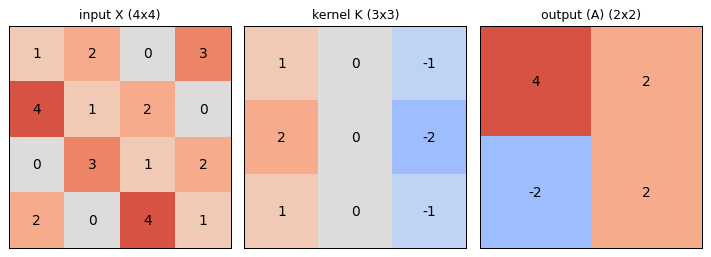

skipped: needs torch


In [3]:
def conv2d(X, K, stride=1, pad=0):
    """Plain 2-D cross-correlation (what deep-learning libraries call convolution)."""
    Xp = np.pad(X, pad)                       # zeros around the border
    k = K.shape[0]
    out = (Xp.shape[0] - k) // stride + 1
    Y = np.zeros((out, out))
    for i in range(out):
        for j in range(out):
            window = Xp[i * stride:i * stride + k, j * stride:j * stride + k]
            Y[i, j] = np.sum(window * K)
    return Y


X = np.array([[1, 2, 0, 3], [4, 1, 2, 0], [0, 3, 1, 2], [2, 0, 4, 1]], dtype=float)
K = np.array([[1, 0, -1], [2, 0, -2], [1, 0, -1]], dtype=float)
Y_A = conv2d(X, K)
Y_B = conv2d(X, K, stride=2, pad=1)
check("(A) stride 1, no padding", Y_A, [[4, 2], [-2, 2]])
check("(B) padding 1, stride 2", Y_B, [[-5, -1], [-7, 2]])

X1 = np.array([[1, 0, 2], [3, 1, 0], [0, 2, 1]], dtype=float)
X2 = np.array([[0, 1, 1], [2, 0, 1], [1, 1, 0]], dtype=float)
K1 = np.array([[1, -1], [0, 2]], dtype=float)
K2 = np.array([[2, 0], [1, -1]], dtype=float)
c1, c2 = conv2d(X1, K1), conv2d(X2, K2)
check("(C) channel 1", c1, [[3, -2], [6, 3]])
check("(C) channel 2", c2, [[2, 1], [4, 1]])
check("(C) sum + bias", c1 + c2 + 1, [[6, 0], [11, 5]])

# Figure: input, kernel and output of part (A), with the numbers written in each cell
fig, axes = plt.subplots(1, 3, figsize=(8, 2.8))
for ax, M, title in zip(axes, [X, K, Y_A], ["input X (4x4)", "kernel K (3x3)", "output (A) (2x2)"]):
    ax.imshow(M, cmap="coolwarm", vmin=-5, vmax=5)
    for (r, c), v in np.ndenumerate(M):
        ax.text(c, r, f"{v:g}", ha="center", va="center", fontsize=11)
    ax.set_title(title, fontsize=10)
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
plt.tight_layout()
plt.show()

try:
    import torch
    import torch.nn.functional as F
    xt = torch.tensor(X).reshape(1, 1, 4, 4)
    kt = torch.tensor(K).reshape(1, 1, 3, 3)
    check("torch conv2d (A)", F.conv2d(xt, kt).squeeze().numpy(), Y_A)
    check("torch conv2d (B)", F.conv2d(xt, kt, stride=2, padding=1).squeeze().numpy(), Y_B)
    x2 = torch.tensor(np.stack([X1, X2])).reshape(1, 2, 3, 3)
    k2 = torch.tensor(np.stack([K1, K2])).reshape(1, 2, 2, 2)
    check("torch conv2d (C)", F.conv2d(x2, k2, bias=torch.tensor([1.0], dtype=torch.float64)).squeeze().numpy(), [[6, 0], [11, 5]])
except ImportError:
    print("skipped: needs torch")

### Try it yourself

Convolve $X = \begin{pmatrix} 1 & 2 & 3 \\ 4 & 5 & 6 \\ 7 & 8 & 9 \end{pmatrix}$ with $K = \begin{pmatrix} 1 & 0 \\ 0 & -1 \end{pmatrix}$ (stride 1, no padding). What would the output size be with padding 1?

<details><summary>Answer</summary>

Each output is (top-left of the window) minus (bottom-right): $1 - 5 = -4$, $2 - 6 = -4$, $4 - 8 = -4$, $5 - 9 = -4$, so $\begin{pmatrix} -4 & -4 \\ -4 & -4 \end{pmatrix}$. With padding 1: $(3 - 2 + 2)/1 + 1 = 4$, so $4\times4$.

</details>

**Common mistake:** flipping the kernel (that is the textbook "true" convolution from signal processing). In CNN exams, unless told otherwise, multiply the kernel as written.

## 3. Max pooling and average pooling

**What it is.** Pooling shrinks a feature map by summarizing each window: **max pooling** keeps the largest value, **average pooling** the mean. A $2\times2$ window with stride 2 halves the width and height. Pooling has **no parameters**. **Global average pooling** averages the whole map into one number per channel (often used just before the final classifier). During backprop, max pooling sends the gradient only to the position of the maximum.

**Everyday analogy.** Summarizing a class photo by keeping only the tallest student in each group of four (max), or the group's average height (average).

### Problem

Apply $2\times2$ max pooling and $2\times2$ average pooling (stride 2) to

$$P = \begin{pmatrix} 1 & 3 & 2 & 1 \\ 4 & 6 & 5 & 0 \\ 7 & 2 & 9 & 4 \\ 1 & 8 & 3 & 5 \end{pmatrix}$$

and also compute the global average pool.

### Solution by hand

The four $2\times2$ blocks are:

| block | values | max | average |
|---|---|---|---|
| top-left | 1, 3, 4, 6 | 6 | $14/4 = 3.5$ |
| top-right | 2, 1, 5, 0 | 5 | $8/4 = 2$ |
| bottom-left | 7, 2, 1, 8 | 8 | $18/4 = 4.5$ |
| bottom-right | 9, 4, 3, 5 | 9 | $21/4 = 5.25$ |

$$\text{max pool} = \begin{pmatrix} 6 & 5 \\ 8 & 9 \end{pmatrix}, \qquad \text{average pool} = \begin{pmatrix} 3.5 & 2 \\ 4.5 & 5.25 \end{pmatrix}$$

Global average pool: the sum of all 16 values is $61$, so $61/16 = 3.8125$.

In [4]:
P = np.array([[1, 3, 2, 1], [4, 6, 5, 0], [7, 2, 9, 4], [1, 8, 3, 5]], dtype=float)
blocks = P.reshape(2, 2, 2, 2).transpose(0, 2, 1, 3)     # blocks[i, j] is the 2x2 window (i, j)
max_pool = blocks.max(axis=(2, 3))
avg_pool = blocks.mean(axis=(2, 3))
check("max pooling", max_pool, [[6, 5], [8, 9]])
check("average pooling", avg_pool, [[3.5, 2.0], [4.5, 5.25]])
check("sum, global average pool", [P.sum(), P.mean()], [61, 3.8125])

max pooling                        numpy = [[6.0000, 5.0000], [8.0000, 9.0000]] hand = [[6.0000, 5.0000], [8.0000, 9.0000]] OK
average pooling                    numpy = [[3.5000, 2.0000], [4.5000, 5.2500]] hand = [[3.5000, 2.0000], [4.5000, 5.2500]] OK
sum, global average pool           numpy = [61.0000, 3.8125]        hand = [61.0000, 3.8125]        OK


### Try it yourself

$2\times2$ max and average pooling (stride 2) of $Q = \begin{pmatrix} 1 & 5 & 2 & 0 \\ 3 & 2 & 8 & 1 \\ 0 & 1 & 4 & 4 \\ 6 & 2 & 3 & 7 \end{pmatrix}$.

<details><summary>Answer</summary>

Blocks: $(1,5,3,2)$, $(2,0,8,1)$, $(0,1,6,2)$, $(4,4,3,7)$. Max pool $\begin{pmatrix} 5 & 8 \\ 6 & 7 \end{pmatrix}$; average pool $\begin{pmatrix} 2.75 & 2.75 \\ 2.25 & 4.5 \end{pmatrix}$.

</details>

**Exam tip:** pooling works on each channel separately, so the number of channels does not change: $28\times28\times8$ becomes $14\times14\times8$.

## 4. Counting parameters: dense, convolution, RNN, LSTM, batch norm

**What it is.** A **parameter** is one learnable number. The rules:

| Layer | Parameters |
|---|---|
| Dense (fully connected) $n_{\text{in}} \to n_{\text{out}}$ | $n_{\text{in}}\cdot n_{\text{out}} + n_{\text{out}}$ |
| Convolution, $C_{\text{out}}$ filters of $K\times K$ over $C_{\text{in}}$ channels | $K\cdot K\cdot C_{\text{in}}\cdot C_{\text{out}} + C_{\text{out}}$ (independent of the image size!) |
| Pooling, flatten, activations | 0 |
| Batch norm over $C$ channels | $2C$ trainable ($\gamma$, $\beta$), plus $2C$ running statistics that are not trained |
| Simple RNN, input $x$, hidden $h$ | $h(x + h) + h$ |
| LSTM (4 gates) / GRU (3 gates) | $4\,[h(x + h) + h]$ / $3\,[h(x + h) + h]$ |

**Everyday analogy.** Counting the knobs on a mixing desk: every connection between two units has one knob, plus one "bias" knob per output.

### Problem

(a) Dense layers $784 \to 128$ and $128 \to 10$.
(b) Convolutions $3\times3$ with $3 \to 16$ channels, and $3\times3$ with $16 \to 32$ channels.
(c) Give the output shape and the parameters of each layer of this model for $28\times28\times1$ images, and the total:
conv $3\times3$, 8 filters, $P = 1$ $\to$ max pool $2\times2$ $\to$ conv $3\times3$, 16 filters, $P = 1$ $\to$ max pool $2\times2$ $\to$ flatten $\to$ dense 32 $\to$ dense 10.
(d) A simple RNN, an LSTM and a GRU layer with input size 10 and hidden size 20.
(e) A batch-norm layer over 64 channels.

### Solution by hand

1. **(a)** $784\cdot128 + 128 = 100{,}352 + 128 = 100{,}480$; $\;128\cdot10 + 10 = 1{,}290$.
2. **(b)** $3\cdot3\cdot3\cdot16 + 16 = 432 + 16 = 448$; $\;3\cdot3\cdot16\cdot32 + 32 = 4{,}608 + 32 = 4{,}640$.
3. **(c)**

| layer | output shape | parameters |
|---|---|---|
| input | $28\times28\times1$ | 0 |
| conv $3\times3$, 8 filters, $P = 1$ | $28\times28\times8$ | $3\cdot3\cdot1\cdot8 + 8 = 80$ |
| max pool $2\times2$ | $14\times14\times8$ | 0 |
| conv $3\times3$, 16 filters, $P = 1$ | $14\times14\times16$ | $3\cdot3\cdot8\cdot16 + 16 = 1{,}168$ |
| max pool $2\times2$ | $7\times7\times16$ | 0 |
| flatten | $7\cdot7\cdot16 = 784$ | 0 |
| dense $784 \to 32$ | 32 | $784\cdot32 + 32 = 25{,}120$ |
| dense $32 \to 10$ | 10 | $32\cdot10 + 10 = 330$ |
| **total** | | $80 + 1{,}168 + 25{,}120 + 330 = 26{,}698$ |

The first dense layer holds 94% of all parameters: convolutions are cheap because they share their weights across the whole image.

4. **(d)** One "unit" of weights: $h(x + h) + h = 20\cdot30 + 20 = 620$. Simple RNN: $620$; LSTM: $4\cdot620 = 2{,}480$; GRU: $3\cdot620 = 1{,}860$. (PyTorch keeps *two* bias vectors per gate, so it reports $640$, $2{,}560$ and $1{,}920$. Say which convention you use.)
5. **(e)** $2\cdot64 = 128$ trainable parameters.

In [5]:
dense = lambda n_in, n_out: n_in * n_out + n_out
conv = lambda k, c_in, c_out: k * k * c_in * c_out + c_out
rnn_unit = lambda x, h: h * (x + h) + h

check("(a) dense 784->128, 128->10", [dense(784, 128), dense(128, 10)], [100_480, 1_290])
check("(b) conv 3x3 3->16, 16->32", [conv(3, 3, 16), conv(3, 16, 32)], [448, 4_640])

side = 28
side = conv_out(side, 3, P=1)            # conv 1 keeps 28
side = conv_out(side, 2, S=2)            # pool -> 14
side = conv_out(side, 3, P=1)            # conv 2 keeps 14
side = conv_out(side, 2, S=2)            # pool -> 7
flat = side * side * 16
layer_params = [conv(3, 1, 8), conv(3, 8, 16), dense(flat, 32), dense(32, 10)]
check("(c) flattened size", flat, 784)
check("(c) parameters per layer", layer_params, [80, 1_168, 25_120, 330])
check("(c) total", sum(layer_params), 26_698)
check("(c) share of the first dense layer", dense(784, 32) / sum(layer_params), 0.9409)
check("(d) RNN, LSTM, GRU", [rnn_unit(10, 20), 4 * rnn_unit(10, 20), 3 * rnn_unit(10, 20)], [620, 2_480, 1_860])
check("(e) batch norm, 64 channels", 2 * 64, 128)

try:
    import torch
    import torch.nn as nn
    count = lambda mod: sum(p.numel() for p in mod.parameters())
    model = nn.Sequential(
        nn.Conv2d(1, 8, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        nn.Conv2d(8, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        nn.Flatten(), nn.Linear(784, 32), nn.ReLU(), nn.Linear(32, 10))
    check("torch: CNN total", count(model), 26_698)
    check("torch: output shape", list(model(torch.zeros(1, 1, 28, 28)).shape), [1, 10])
    check("torch: RNN, LSTM, GRU (two biases)", [count(nn.RNN(10, 20)), count(nn.LSTM(10, 20)), count(nn.GRU(10, 20))], [640, 2_560, 1_920])
    check("torch: BatchNorm2d(64)", count(nn.BatchNorm2d(64)), 128)
except ImportError:
    print("skipped: needs torch")

(a) dense 784->128, 128->10        numpy = [100480.0000, 1290.0000] hand = [100480.0000, 1290.0000] OK
(b) conv 3x3 3->16, 16->32         numpy = [448.0000, 4640.0000]    hand = [448.0000, 4640.0000]    OK
(c) flattened size                 numpy = 784.0000                 hand = 784.0000                 OK
(c) parameters per layer           numpy = [80.0000, 1168.0000, 25120.0000, 330.0000] hand = [80.0000, 1168.0000, 25120.0000, 330.0000] OK
(c) total                          numpy = 26698.0000               hand = 26698.0000               OK
(c) share of the first dense layer numpy = 0.9409                   hand = 0.9409                   OK
(d) RNN, LSTM, GRU                 numpy = [620.0000, 2480.0000, 1860.0000] hand = [620.0000, 2480.0000, 1860.0000] OK
(e) batch norm, 64 channels        numpy = 128.0000                 hand = 128.0000                 OK
skipped: needs torch


### Try it yourself

(a) A conv layer with 6 filters of $5\times5$ on an RGB image ($C_{\text{in}} = 3$). (b) A dense layer $400 \to 120$. (c) A $32\times32\times3$ image goes through that conv layer (no padding, stride 1) and then a $2\times2$ max pool: what is the output shape?

<details><summary>Answer</summary>

(a) $5\cdot5\cdot3\cdot6 + 6 = 450 + 6 = 456$. (b) $400\cdot120 + 120 = 48{,}120$. (c) Conv: $32 - 5 + 1 = 28$, so $28\times28\times6$; pool: $14\times14\times6$.

</details>

**Common mistake:** multiplying by the image size when counting convolution parameters. The same small filter is reused at every position, so the image size changes the output shape and the amount of computation, but not the number of parameters.

## 5. A simple RNN: two time steps

**What it is.** A recurrent neural network reads a sequence $x_1, x_2, \dots$ one element at a time and keeps a **hidden state** $h_t$, its running memory:

$$h_t = \tanh(w_x\,x_t + w_h\,h_{t-1} + b), \qquad \hat y_t = w_y\,h_t$$

The **same** weights $w_x, w_h, b$ are used at every time step. (With vectors: $h_t = \tanh(W_x x_t + W_h h_{t-1} + b)$.) During training, backpropagation through time multiplies one factor $\partial h_t/\partial h_{t-1} = w_h\,(1 - h_t^2)$ per step, which is why plain RNNs forget long-range information (vanishing gradients, Part 1 Section 11).

**Everyday analogy.** Reading a story one word at a time while keeping a one-sentence summary in your head; each new word updates the summary.

### Problem

A scalar RNN with $w_x = 0.5$, $w_h = 0.8$, $b = 0.1$, output weight $w_y = 2$, and $h_0 = 0$ reads the inputs $x_1 = 1.0$, $x_2 = 2.0$. Compute $h_1$, $h_2$, the output $\hat y_2$, and the gradient factor $\partial h_2/\partial h_1$.

### Solution by hand

1. $t = 1$: pre-activation $a_1 = 0.5\cdot1.0 + 0.8\cdot0 + 0.1 = 0.6$, so $h_1 = \tanh(0.6) = 0.5370$
2. $t = 2$: $a_2 = 0.5\cdot2.0 + 0.8\cdot0.5370 + 0.1 = 1.0 + 0.4296 + 0.1 = 1.5296$, so $h_2 = \tanh(1.5296) = 0.9104$
3. Output: $\hat y_2 = 2\cdot0.9104 = 1.8207$
4. Gradient factor: $\dfrac{\partial h_2}{\partial h_1} = w_h\,(1 - h_2^2) = 0.8\cdot(1 - 0.8288) = 0.8\cdot0.1712 = 0.1370$. Over many steps such factors multiply: a signal from 10 steps back would be scaled by roughly $0.137^{10}$, essentially zero.

In [6]:
w_x, w_h, b, w_y = 0.5, 0.8, 0.1, 2.0
h = 0.0
pre, hs = [], []
for x_t in [1.0, 2.0]:
    a_t = w_x * x_t + w_h * h + b
    h = np.tanh(a_t)
    pre.append(a_t)
    hs.append(h)
check("pre-activations a1, a2", pre, [0.6, 1.5296])
check("hidden states h1, h2", hs, [0.5370, 0.9104])
check("w_h * h1", w_h * hs[0], 0.4296)
check("output y_hat_2", w_y * hs[1], 1.8207)
check("1 - h2^2", 1 - hs[1] ** 2, 0.1712)
check("dh2/dh1 = w_h (1 - h2^2)", w_h * (1 - hs[1] ** 2), 0.1370)

pre-activations a1, a2             numpy = [0.6000, 1.5296]         hand = [0.6000, 1.5296]         OK
hidden states h1, h2               numpy = [0.5370, 0.9104]         hand = [0.5370, 0.9104]         OK
w_h * h1                           numpy = 0.4296                   hand = 0.4296                   OK
output y_hat_2                     numpy = 1.8207                   hand = 1.8207                   OK
1 - h2^2                           numpy = 0.1712                   hand = 0.1712                   OK
dh2/dh1 = w_h (1 - h2^2)           numpy = 0.1370                   hand = 0.1370                   OK


### Try it yourself

$w_x = 1$, $w_h = 0.5$, $b = 0$, $h_0 = 0$, inputs $x_1 = x_2 = 1$. Compute $h_1$ and $h_2$.

<details><summary>Answer</summary>

$h_1 = \tanh(1) = 0.7616$. $a_2 = 1 + 0.5\cdot0.7616 = 1.3808$, so $h_2 = \tanh(1.3808) = 0.8811$.

</details>

**Common mistake:** using different weights at each time step. An RNN has **one** set of weights shared across all steps; unrolling it in time only repeats the same cell.

## 6. One LSTM step with all four gates

**What it is.** An LSTM cell keeps two memories: the **cell state** $c_t$ (long-term) and the **hidden state** $h_t$ (what it outputs). Gates are sigmoid "valves" between 0 (closed) and 1 (open):

| piece | formula | role |
|---|---|---|
| forget gate | $f = \sigma(w_f x_t + u_f h_{t-1} + b_f)$ | how much old memory to keep |
| input gate | $i = \sigma(w_i x_t + u_i h_{t-1} + b_i)$ | how much new information to write |
| candidate | $g = \tanh(w_g x_t + u_g h_{t-1} + b_g)$ | the new information itself |
| output gate | $o = \sigma(w_o x_t + u_o h_{t-1} + b_o)$ | how much memory to show |
| cell state | $c_t = f\cdot c_{t-1} + i\cdot g$ | |
| hidden state | $h_t = o\cdot\tanh(c_t)$ | |

The cell state is updated by an **addition**, so gradients can flow back through many steps (scaled by $f$, not squashed by a $\tanh'$ each time). That is how LSTMs fight vanishing gradients.

**Everyday analogy.** A notebook you carry around: each day you erase some old notes (forget gate), write some new ones (input gate and candidate), and decide which notes to read out loud (output gate).

### Problem

One step of a scalar LSTM with $x_t = 1.0$, $h_{t-1} = 0.5$, $c_{t-1} = 0.8$ and these weights:

| gate | $w$ (for $x_t$) | $u$ (for $h_{t-1}$) | $b$ |
|---|---|---|---|
| forget $f$ | 0.5 | 0.4 | 0.1 |
| input $i$ | 0.6 | -0.2 | 0.0 |
| output $o$ | 0.3 | 0.2 | 0.2 |
| candidate $g$ | 0.7 | 0.6 | -0.2 |

Compute $f, i, o, g$, the new cell state $c_t$ and the new hidden state $h_t$.

### Solution by hand

1. $z_f = 0.5\cdot1 + 0.4\cdot0.5 + 0.1 = 0.8$, so $f = \sigma(0.8) = 0.6900$
2. $z_i = 0.6\cdot1 - 0.2\cdot0.5 + 0 = 0.5$, so $i = \sigma(0.5) = 0.6225$
3. $z_o = 0.3\cdot1 + 0.2\cdot0.5 + 0.2 = 0.6$, so $o = \sigma(0.6) = 0.6457$
4. $z_g = 0.7\cdot1 + 0.6\cdot0.5 - 0.2 = 0.8$, so $g = \tanh(0.8) = 0.6640$
5. $c_t = f\cdot c_{t-1} + i\cdot g = 0.6900\cdot0.8 + 0.6225\cdot0.6640 = 0.5520 + 0.4133 = 0.9653$
6. $h_t = o\cdot\tanh(c_t) = 0.6457\cdot\tanh(0.9653) = 0.6457\cdot0.7466 = 0.4821$

The cell kept 69% of its old memory ($0.5520$ of $0.8$) and added $0.4133$ of new information.

In [7]:
x_t, h_prev, c_prev = 1.0, 0.5, 0.8
weights = {"f": (0.5, 0.4, 0.1), "i": (0.6, -0.2, 0.0), "o": (0.3, 0.2, 0.2), "g": (0.7, 0.6, -0.2)}
z = {k: w * x_t + u * h_prev + b for k, (w, u, b) in weights.items()}
f_gate, i_gate, o_gate = sigmoid(z["f"]), sigmoid(z["i"]), sigmoid(z["o"])
g_cand = np.tanh(z["g"])
c_t = f_gate * c_prev + i_gate * g_cand
h_t = o_gate * np.tanh(c_t)

check("pre-activations z_f, z_i, z_o, z_g", [z["f"], z["i"], z["o"], z["g"]], [0.8, 0.5, 0.6, 0.8])
check("gates f, i, o", [f_gate, i_gate, o_gate], [0.6900, 0.6225, 0.6457])
check("candidate g", g_cand, 0.6640)
check("f*c_prev, i*g", [f_gate * c_prev, i_gate * g_cand], [0.5520, 0.4133])
check("cell state c_t", c_t, 0.9653)
check("tanh(c_t)", np.tanh(c_t), 0.7466)
check("hidden state h_t", h_t, 0.4821)

pre-activations z_f, z_i, z_o, z_g numpy = [0.8000, 0.5000, 0.6000, 0.8000] hand = [0.8000, 0.5000, 0.6000, 0.8000] OK
gates f, i, o                      numpy = [0.6900, 0.6225, 0.6457] hand = [0.6900, 0.6225, 0.6457] OK
candidate g                        numpy = 0.6640                   hand = 0.6640                   OK
f*c_prev, i*g                      numpy = [0.5520, 0.4133]         hand = [0.5520, 0.4133]         OK
cell state c_t                     numpy = 0.9653                   hand = 0.9653                   OK
tanh(c_t)                          numpy = 0.7466                   hand = 0.7466                   OK
hidden state h_t                   numpy = 0.4821                   hand = 0.4821                   OK


### Try it yourself

$x_t = 2$, $h_{t-1} = 0$, $c_{t-1} = 1$. Because $h_{t-1} = 0$, only the $w$ and $b$ values matter: forget $w = -1$, $b = 0$; input $w = 0.5$, $b = 0$; output $w = 0$, $b = 0$; candidate $w = 0.25$, $b = 0$. Compute $f, i, o, g, c_t, h_t$.

<details><summary>Answer</summary>

$f = \sigma(-2) = 0.1192$, $i = \sigma(1) = 0.7311$, $o = \sigma(0) = 0.5$, $g = \tanh(0.5) = 0.4621$.
$c_t = 0.1192\cdot1 + 0.7311\cdot0.4621 = 0.1192 + 0.3378 = 0.4570$; $h_t = 0.5\cdot\tanh(0.4570) = 0.5\cdot0.4277 = 0.2138$. The forget gate threw away almost 90% of the old memory.

</details>

**Exam tip:** the gates use **sigmoid** (a valve between 0 and 1); the candidate and the final squashing use **tanh** (values between -1 and 1). A GRU merges the forget and input gates into one "update" gate and has no separate cell state.

## 7. Scaled dot-product attention

**What it is.** Each token has a **query** $q$ ("what am I looking for?"), a **key** $k$ ("what do I contain?") and a **value** $v$ ("what do I pass on?"). Attention compares every query with every key, turns the scores into weights with softmax, and averages the values:

$$\text{Attention}(Q, K, V) = \operatorname{softmax}\!\left(\frac{QK^\top}{\sqrt{d_k}}\right)V$$

Dividing by $\sqrt{d_k}$ ($d_k$ = length of a key vector) keeps the scores from growing with the vector length, which would make the softmax too peaked and the gradients tiny.

**Everyday analogy.** A library search: your question (query) is compared with the label on every book (keys); you then read a mix of the books (values), mostly the ones whose labels matched best.

### Problem

Three tokens with $d_k = 2$:

$$Q = \begin{pmatrix} 1 & 0 \\ 0 & 1 \\ 1 & 1 \end{pmatrix}, \quad K = \begin{pmatrix} 1 & 1 \\ 0 & 1 \\ 1 & 0 \end{pmatrix}, \quad V = \begin{pmatrix} 1 & 0 \\ 0 & 2 \\ 1 & 1 \end{pmatrix}$$

(row $i$ belongs to token $i$). Compute the scores, the scaled scores, the attention weights and the output.

### Solution by hand

1. **Scores** $S = QK^\top$, entry $(i, j) = q_i\cdot k_j$. For $q_1 = (1, 0)$: $k_1 = (1,1) \to 1$, $k_2 = (0,1) \to 0$, $k_3 = (1,0) \to 1$. Likewise for $q_2$ and $q_3$:

$$S = \begin{pmatrix} 1 & 0 & 1 \\ 1 & 1 & 0 \\ 2 & 1 & 1 \end{pmatrix}$$

2. **Scale** by $\sqrt{2} = 1.4142$: $\;1/1.4142 = 0.7071$ and $2/1.4142 = 1.4142$:

$$S/\sqrt{d_k} = \begin{pmatrix} 0.7071 & 0 & 0.7071 \\ 0.7071 & 0.7071 & 0 \\ 1.4142 & 0.7071 & 0.7071 \end{pmatrix}$$

3. **Softmax of each row** (subtract the row maximum first):
   - Row 1: shifted $(0, -0.7071, 0)$, exponentials $(1, 0.4931, 1)$, sum $2.4931$, weights $(0.4011, 0.1978, 0.4011)$.
   - Row 2: the same numbers in a different order: $(0.4011, 0.4011, 0.1978)$.
   - Row 3: shifted $(0, -0.7071, -0.7071)$, exponentials $(1, 0.4931, 0.4931)$, sum $1.9861$, weights $(0.5035, 0.2483, 0.2483)$.
4. **Weighted sum of the values** (each row of weights times $V$):
   - Token 1: $0.4011\cdot(1,0) + 0.1978\cdot(0,2) + 0.4011\cdot(1,1) = (0.4011 + 0.4011,\ 0.3956 + 0.4011) = (0.8022, 0.7967)$
   - Token 2: $0.4011\cdot(1,0) + 0.4011\cdot(0,2) + 0.1978\cdot(1,1) = (0.4011 + 0.1978,\ 0.8022 + 0.1978) = (0.5989, 1.0000)$
   - Token 3: $0.5035\cdot(1,0) + 0.2483\cdot(0,2) + 0.2483\cdot(1,1)$. First entry $= 0.5035 + 0.2483 = 1 - 0.2483 = 0.7517$ (the weights sum to 1); second entry $= 3\cdot0.2483 = 0.7448$ (with full precision, $3\cdot0.248255$).

$$\text{output} = \begin{pmatrix} 0.8022 & 0.7967 \\ 0.5989 & 1.0000 \\ 0.7517 & 0.7448 \end{pmatrix}$$

Token 3's query $(1, 1)$ matches key 1 best (score 2), so it gives token 1 the largest weight.

scores Q K^T                       numpy = [[1.0000, 0.0000, 1.0000], [1.0000, 1.0000, 0.0000], [2.0000, 1.0000, 1.0000]] hand = [[1.0000, 0.0000, 1.0000], [1.0000, 1.0000, 0.0000], [2.0000, 1.0000, 1.0000]] OK
scaled scores                      numpy = [[0.7071, 0.0000, 0.7071], [0.7071, 0.7071, 0.0000], [1.4142, 0.7071, 0.7071]] hand = [[0.7071, 0.0000, 0.7071], [0.7071, 0.7071, 0.0000], [1.4142, 0.7071, 0.7071]] OK
row sums of exponentials           numpy = [2.4931, 2.4931, 1.9861] hand = [2.4931, 2.4931, 1.9861] OK
attention weights                  numpy = [[0.4011, 0.1978, 0.4011], [0.4011, 0.4011, 0.1978], [0.5035, 0.2483, 0.2483]] hand = [[0.4011, 0.1978, 0.4011], [0.4011, 0.4011, 0.1978], [0.5035, 0.2483, 0.2483]] OK
each row sums to 1                 numpy = [1.0000, 1.0000, 1.0000] hand = [1.0000, 1.0000, 1.0000] OK
output = weights @ V               numpy = [[0.8022, 0.7967], [0.5989, 1.0000], [0.7517, 0.7448]] hand = [[0.8022, 0.7967], [0.5989, 1.0000], [0.7517, 0.7448]] O

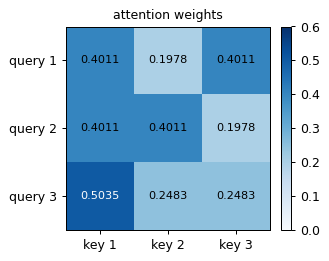

skipped: needs torch


In [8]:
Q = np.array([[1, 0], [0, 1], [1, 1]], dtype=float)
K = np.array([[1, 1], [0, 1], [1, 0]], dtype=float)
V = np.array([[1, 0], [0, 2], [1, 1]], dtype=float)
d_k = Q.shape[1]

S = Q @ K.T
S_scaled = S / np.sqrt(d_k)
E = np.exp(S_scaled - S_scaled.max(axis=1, keepdims=True))
A = E / E.sum(axis=1, keepdims=True)
out = A @ V

check("scores Q K^T", S, [[1, 0, 1], [1, 1, 0], [2, 1, 1]])
check("scaled scores", S_scaled, [[0.7071, 0, 0.7071], [0.7071, 0.7071, 0], [1.4142, 0.7071, 0.7071]])
check("row sums of exponentials", E.sum(axis=1), [2.4931, 2.4931, 1.9861])
check("attention weights", A, [[0.4011, 0.1978, 0.4011], [0.4011, 0.4011, 0.1978], [0.5035, 0.2483, 0.2483]])
check("each row sums to 1", A.sum(axis=1), [1, 1, 1])
check("output = weights @ V", out, [[0.8022, 0.7967], [0.5989, 1.0], [0.7517, 0.7448]])

fig, ax = plt.subplots(figsize=(3.6, 3))
im = ax.imshow(A, cmap="Blues", vmin=0, vmax=0.6)
for (r, c), v in np.ndenumerate(A):
    ax.text(c, r, f"{v:.4f}", ha="center", va="center", fontsize=9, color="white" if v > 0.45 else "black")
ax.set_xticks(range(3), ["key 1", "key 2", "key 3"])
ax.set_yticks(range(3), ["query 1", "query 2", "query 3"])
ax.set_title("attention weights", fontsize=10)
ax.grid(False)
plt.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout()
plt.show()

try:
    import torch
    qt, kt, vt = (torch.tensor(M) for M in (Q, K, V))
    weights_t = torch.softmax(qt @ kt.T / math.sqrt(d_k), dim=-1)
    check("torch attention output", (weights_t @ vt).numpy(), out)
except ImportError:
    print("skipped: needs torch")

### Try it yourself

One query $q = (1, 1)$ attends over two tokens with keys $k_1 = (1, 0)$, $k_2 = (1, 2)$ and values $v_1 = (2, 0)$, $v_2 = (0, 2)$; $d_k = 2$. Compute the scaled scores, the weights and the output.

<details><summary>Answer</summary>

Scores $(1, 3)$; scaled $(0.7071, 2.1213)$. Shift by the maximum: $(-1.4142, 0)$, exponentials $(0.2431, 1)$, sum $1.2431$, weights $(0.1956, 0.8044)$. Output $= 0.1956\cdot(2, 0) + 0.8044\cdot(0, 2) = (0.3911, 1.6089)$.

</details>

**Exam tip:** in a decoder (causal) self-attention, token $i$ may not look at later tokens: their scores are set to $-\infty$ before the softmax, so their weights become exactly 0. For token 1 above that would leave only key 1, with weight 1, and the output would be $v_1$.

## 8. Word embeddings: cosine similarity

**What it is.** An **embedding** represents a word (or token) as a vector of numbers, learned so that words used in similar contexts end up pointing in similar directions. **Cosine similarity** measures the angle between two vectors, ignoring their lengths:

$$\cos(a, b) = \frac{a\cdot b}{\lVert a\rVert\,\lVert b\rVert}$$

It is $1$ for the same direction, $0$ for unrelated (perpendicular) vectors and $-1$ for opposite directions.

**Everyday analogy.** Two people who point in almost the same direction are "pointing at the same thing", even if one has a longer arm.

### Problem

Three 3-dimensional word vectors: $\text{cat} = (1, 2, 2)$, $\text{dog} = (2, 1, 2)$, $\text{car} = (-1, -2, 2)$. Compute the three cosine similarities and the Euclidean distances cat-dog and cat-car. Which pair is most similar?

### Solution by hand

1. Lengths: $\lVert\text{cat}\rVert = \sqrt{1 + 4 + 4} = 3$; $\;\lVert\text{dog}\rVert = \sqrt{4 + 1 + 4} = 3$; $\;\lVert\text{car}\rVert = \sqrt{1 + 4 + 4} = 3$
2. cat $\cdot$ dog $= 1\cdot2 + 2\cdot1 + 2\cdot2 = 8$, so $\cos = 8/9 = 0.8889$
3. cat $\cdot$ car $= -1 - 4 + 4 = -1$, so $\cos = -1/9 = -0.1111$
4. dog $\cdot$ car $= -2 - 2 + 4 = 0$, so $\cos = 0$ (perpendicular: unrelated)
5. Distances: $\lVert\text{cat} - \text{dog}\rVert = \lVert(-1, 1, 0)\rVert = \sqrt{2} = 1.4142$; $\;\lVert\text{cat} - \text{car}\rVert = \lVert(2, 4, 0)\rVert = \sqrt{20} = 4.4721$

**Answer:** cat and dog are by far the most similar (cosine $0.8889$, smallest distance).

In [9]:
cat, dog, car = np.array([1.0, 2.0, 2.0]), np.array([2.0, 1.0, 2.0]), np.array([-1.0, -2.0, 2.0])
cosine = lambda a, b: a @ b / (np.linalg.norm(a) * np.linalg.norm(b))
check("lengths", [np.linalg.norm(v) for v in (cat, dog, car)], [3, 3, 3])
check("dot products cat.dog, cat.car, dog.car", [cat @ dog, cat @ car, dog @ car], [8, -1, 0])
check("cosine cat-dog, cat-car, dog-car", [cosine(cat, dog), cosine(cat, car), cosine(dog, car)], [0.8889, -0.1111, 0.0])
check("distances cat-dog, cat-car", [np.linalg.norm(cat - dog), np.linalg.norm(cat - car)], [1.4142, 4.4721])

lengths                            numpy = [3.0000, 3.0000, 3.0000] hand = [3.0000, 3.0000, 3.0000] OK
dot products cat.dog, cat.car, dog.car numpy = [8.0000, -1.0000, 0.0000] hand = [8.0000, -1.0000, 0.0000] OK
cosine cat-dog, cat-car, dog-car   numpy = [0.8889, -0.1111, 0.0000] hand = [0.8889, -0.1111, 0.0000] OK
distances cat-dog, cat-car         numpy = [1.4142, 4.4721]         hand = [1.4142, 4.4721]         OK


### Try it yourself

Cosine similarity of (a) $(1, 0, 1)$ and $(0, 1, 1)$; (b) $(3, 4)$ and $(4, 3)$.

<details><summary>Answer</summary>

(a) $1/(\sqrt2\cdot\sqrt2) = 1/2 = 0.5$. (b) $(12 + 12)/(5\cdot5) = 24/25 = 0.96$.

</details>

**Exam tip:** for vectors of length 1 (as many embedding models output), cosine similarity equals the plain dot product, and $\lVert a - b\rVert^2 = 2 - 2\cos(a, b)$, so ranking by cosine or by distance gives the same order.

## 9. Perplexity of a language model

**What it is.** A language model gives a probability to each next token. On a text of $N$ tokens, take the probability $p_i$ it gave to each **correct** token. The average cross-entropy is $H = -\frac{1}{N}\sum_i \ln p_i$, and the **perplexity** is

$$\text{PPL} = e^{H} = \Big(\prod_i p_i\Big)^{-1/N}$$

Perplexity is "how many tokens the model is effectively choosing between": a perfect model has $\text{PPL} = 1$, and guessing uniformly among $V$ tokens gives $\text{PPL} = V$. Lower is better. (With $\log_2$ you get $H$ in bits and $\text{PPL} = 2^{H}$: the same number.)

**Everyday analogy.** A quiz contestant with perplexity 3 is as unsure as someone choosing between 3 equally likely answers on every question.

### Problem

A model reads a 4-token sentence and gives the correct next tokens the probabilities $0.5, 0.25, 0.8, 0.1$. Compute the average cross-entropy (in nats and in bits) and the perplexity.

### Solution by hand

1. Logarithms: $\ln 0.5 = -0.6931$, $\ln 0.25 = -1.3863$, $\ln 0.8 = -0.2231$, $\ln 0.1 = -2.3026$; sum $= -4.6052$
2. $H = 4.6052/4 = 1.1513$ nats
3. $\text{PPL} = e^{1.1513} = 3.1623$
4. Shortcut: the product is $0.5\cdot0.25\cdot0.8\cdot0.1 = 0.01$, so $\text{PPL} = 0.01^{-1/4} = 100^{1/4} = \sqrt{10} = 3.1623$
5. In bits: $H = 1.1513/\ln 2 = 1.6610$ bits, and $2^{1.6610} = 3.1623$: the same perplexity.

In [10]:
p = np.array([0.5, 0.25, 0.8, 0.1])
logs = np.log(p)
H = -logs.mean()
check("ln p", logs, [-0.6931, -1.3863, -0.2231, -2.3026])
check("sum of ln p", logs.sum(), -4.6052)
check("cross-entropy H (nats)", H, 1.1513)
check("perplexity e^H", np.exp(H), 3.1623)
check("product of p, product^(-1/N)", [np.prod(p), np.prod(p) ** (-1 / 4)], [0.01, 3.1623])
H_bits = -np.log2(p).mean()
check("H in bits, 2^H", [H_bits, 2**H_bits], [1.6610, 3.1623])
check("uniform over 50,000 tokens", np.exp(-np.log(1 / 50_000)), 50_000)

ln p                               numpy = [-0.6931, -1.3863, -0.2231, -2.3026] hand = [-0.6931, -1.3863, -0.2231, -2.3026] OK
sum of ln p                        numpy = -4.6052                  hand = -4.6052                  OK
cross-entropy H (nats)             numpy = 1.1513                   hand = 1.1513                   OK
perplexity e^H                     numpy = 3.1623                   hand = 3.1623                   OK
product of p, product^(-1/N)       numpy = [0.0100, 3.1623]         hand = [0.0100, 3.1623]         OK
H in bits, 2^H                     numpy = [1.6610, 3.1623]         hand = [1.6610, 3.1623]         OK
uniform over 50,000 tokens         numpy = 50000.0000               hand = 50000.0000               OK


### Try it yourself

The correct tokens get probabilities $0.25, 0.5, 0.5, 0.125$. Compute the perplexity (hint: write each probability as a power of 2) and the cross-entropy in nats.

<details><summary>Answer</summary>

Product $= 2^{-2}\cdot2^{-1}\cdot2^{-1}\cdot2^{-3} = 2^{-7} = 0.0078125$, so $\text{PPL} = (2^{-7})^{-1/4} = 2^{7/4} = 3.3636$. $H = \ln 3.3636 = 1.2130$ nats (or $7/4 = 1.75$ bits).

</details>

**Common mistake:** averaging the probabilities instead of their logarithms. Perplexity uses the **geometric** mean, so one very unlikely token (such as $0.1$ above) raises it a lot.

## Recap cheat sheet

| # | Topic | Formula / rule |
|---|---|---|
| 1 | Output size | $O = \lfloor (W - K + 2P)/S\rfloor + 1$; "same" padding $P = (K-1)/2$ for $S = 1$; channels out $=$ number of filters |
| 2 | Convolution | slide, multiply element-wise, sum (+ bias); no kernel flip; multi-channel: one slice per input channel, sum over channels |
| 3 | Pooling | max or mean of each window; no parameters; channels unchanged; global average pool $=$ mean of the whole map |
| 4 | Parameters | dense $n_{\text{in}}n_{\text{out}} + n_{\text{out}}$; conv $K^2C_{\text{in}}C_{\text{out}} + C_{\text{out}}$; BN $2C$; RNN $h(x+h)+h$; LSTM $\times4$; GRU $\times3$ (PyTorch: two bias vectors) |
| 5 | RNN | $h_t = \tanh(w_xx_t + w_hh_{t-1} + b)$, shared weights; $\partial h_t/\partial h_{t-1} = w_h(1 - h_t^2)$ |
| 6 | LSTM | $f, i, o = \sigma(\cdot)$, $g = \tanh(\cdot)$; $c_t = f c_{t-1} + i g$; $h_t = o\tanh(c_t)$ |
| 7 | Attention | $\operatorname{softmax}(QK^\top/\sqrt{d_k})\,V$; each row of weights sums to 1; causal mask $= -\infty$ before softmax |
| 8 | Cosine similarity | $a\cdot b/(\lVert a\rVert\lVert b\rVert)$, from $-1$ to $1$ |
| 9 | Perplexity | $\text{PPL} = \exp(-\frac1N\sum\ln p_i) = (\prod p_i)^{-1/N}$; uniform over $V$ tokens gives $V$ |

## Related notebooks in this repo

- [Deep learning numericals, part 1](00b_dl_numericals_solved_by_hand.ipynb): neurons, activations, backprop, initialization, normalization, regularization, optimizers, learning rates and structuring ML projects.
- [CNNs](03_cnn.ipynb) and [RNNs, LSTMs and GRUs](04_rnn_lstm_gru.ipynb): the theory behind Sections 1-6, with trained models.
- [Transformers architecture](05_transformers_architecture.ipynb): attention, multi-head attention and the full Transformer block.
- [Neural networks from scratch in NumPy](18_neural_networks_from_scratch_numpy.ipynb): Conv2D via im2col and max pooling implemented and gradient-checked.
- [Sequence models hands-on](19_sequence_models_hands_on.ipynb): RNN, LSTM and GRU cells from scratch, backpropagation through time and attention.
- [Deep learning mechanics: math and code reference](22_deep_learning_mechanics_math_and_code_reference.ipynb): one reference for the mechanics behind all of these layers.
- [Start here: images and your first CNN](../06_Computer_Vision/00_start_here_images_and_your_first_cnn.ipynb) and [CV numericals solved by hand](../06_Computer_Vision/00b_cv_numericals_solved_by_hand.ipynb): IoU, non-max suppression, receptive fields and more vision arithmetic.
- [Word embeddings](../07_NLP/02_word_embeddings.ipynb) and [NLP numericals solved by hand](../07_NLP/00b_nlp_numericals_solved_by_hand.ipynb): word2vec, BLEU, beam search and n-gram arithmetic.
- [Transformer and LLM mechanics: math and code](../08_LLM/30_transformer_and_llm_mechanics_math_and_code.ipynb) and [LLM and GenAI numericals solved by hand](../08_LLM/00b_llm_and_genai_numericals_solved_by_hand.ipynb): Transformer parameter counts, KV cache, LoRA and sampling.

## Additional Learning Resources

- **Stanford CS231n course notes, "Convolutional Neural Networks"** (free): output-size arithmetic, parameter sharing and pooling, with the same formulas as Sections 1-4. https://cs231n.github.io/convolutional-networks/
- **Dumoulin and Visin, "A guide to convolution arithmetic for deep learning"** (arXiv:1603.07285): every padding/stride case, with pictures. https://arxiv.org/abs/1603.07285
- **CNN Explainer** (interactive, free): watch a small CNN convolve and pool real images. https://poloclub.github.io/cnn-explainer/
- **Christopher Olah, "Understanding LSTM Networks"** (blog post): the clearest picture-by-picture walk through the LSTM gates. https://colah.github.io/posts/2015-08-Understanding-LSTMs/
- **Jay Alammar, "The Illustrated Transformer"** (blog post): queries, keys, values and attention weights drawn step by step. https://jalammar.github.io/illustrated-transformer/
- **Dive into Deep Learning (d2l.ai)** (free, with code): chapters on convolutional networks, recurrent networks and attention mechanisms. https://d2l.ai/
- **3Blue1Brown, "Neural networks" series** (free): includes visual chapters on attention and Transformers. https://www.3blue1brown.com/topics/neural-networks
- **Michael Nielsen, *Neural Networks and Deep Learning*** (free online book), chapter 6 on convolutional networks. http://neuralnetworksanddeeplearning.com/
- Original papers: LeCun et al. (1998), "Gradient-based learning applied to document recognition"; Hochreiter and Schmidhuber (1997), "Long Short-Term Memory"; Vaswani et al. (2017), "Attention Is All You Need" (arXiv:1706.03762); Mikolov et al. (2013), "Efficient Estimation of Word Representations in Vector Space" (arXiv:1301.3781).